In [130]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from collections import Counter
from scipy.spatial.distance import jensenshannon

In [131]:
data_type = pd.read_json("outputs/textonly_dataframes/bbc-news/counts_type.json")
data_entity = pd.read_json("outputs/textonly_dataframes/bbc-news/counts_entity.json")

In [132]:
# plot enity TYPES at different iterations

def plot_entity_types(data, entity_types: list | None = None, figsize=(12, 6), save_path=None, title=None):
    marker_cycle = ("o", "s")
    line_style = {"linewidth": 2}
    marker_style = {"markeredgecolor": "black", "markeredgewidth": 0.5, "linestyle": "none"}

    iterations = ["original"] + [col for col in data.iteration.unique() if col.startswith("iteration_")]
    fig, ax = plt.subplots(figsize=figsize, layout="tight")

    entity_types = entity_types if entity_types else sorted(data['entity'].unique())
    for et in entity_types:
        counts = [
            data[(data["iteration"] == it) & (data["entity"] == et)]["count"].sum()
            for it in iterations
        ]
    
        # Line without markers; grab its color so markers match
        (line,) = ax.plot(iterations, counts, label=et, **line_style)
        color = line.get_color()

        # Overlay markers, alternating by position
        for m_idx, m in enumerate(marker_cycle):
            xs = iterations[m_idx::len(marker_cycle)]
            ys = counts[m_idx::len(marker_cycle)]
            ax.plot(xs, ys, marker=m, color=color, **marker_style)


    ax.set_xticks(range(len(iterations)), ["original"] + list(range(1, len(iterations))))
    first = ax.get_xticklabels()[0]
    first.set_rotation(90)
    first.set_ha("center")
            
    ax.set_xlabel('Iterations')
    ax.set_ylabel('Count')

    _title = title if title else (f'Entity Type' if entity_types else 'All Entity Types')
    ax.set_title(_title)

    # color the background of the original iteration differently (iter 0)
    ax.axvspan(-0.5, 0.5, alpha=0.7, color='lightgray')

    plt.grid(which='major', linestyle='--', alpha=0.7)

    # set legend below the plot
    ax.legend(bbox_to_anchor=(0.5, -0.10), loc='upper center', ncol=len(entity_types) // 2)

In [133]:
import numpy as np

def plot_sample_trajectory(data, sample_id, figsize=(12, 12), save_path=None, title=None):
    # sample = data[data["document_ids"].apply(lambda ids: sample_id in ids)]
    sample = data[data["document_ids"] == sample_id]
    if sample.empty:
        print(f"No sample found with document ID {sample_id}.")
        return

    iterations = ["original"] + [col for col in data.iteration.unique() if col.startswith("iteration_")]
    vocab = sample.entity.unique()

    # create a heatmap of the sample's entity counts across iterations
    heatmap_data = pd.DataFrame(index=vocab, columns=iterations)

    for it in iterations:
        for entity in vocab:
            if entity in sample[sample["iteration"] == it]["entity"].values:
                count = sample[(sample["iteration"] == it) & (sample["entity"] == entity)]["count"].sum()
            else:
                count = 0
            heatmap_data.at[entity, it] = count

    heatmap_data = heatmap_data.astype(float)

    # Plot the heatmap
    fig, ax = plt.subplots(figsize=figsize, layout="tight")
    im = ax.imshow(heatmap_data, cmap='viridis', aspect="equal")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax.set_yticks(range(len(vocab)), vocab)
    ax.set_xticks(range(len(iterations)))

    # set grid # TODO: this is slightly off - is there a better way to do this? (you can see the grid lines are not perfectly aligned with the cells)
    ax.set_yticks(np.arange(-0.5, len(vocab), 1), minor=True)
    ax.set_xticks(np.arange(-0.5, len(iterations), 1), minor=True)
    plt.grid(which="minor", color="white", linewidth=0.9)
    plt.tick_params(which="minor", length=0)

In [141]:
def compare_counters(src: Counter, tgt: Counter, seen: set | None = None):
    """
    src: original counter; tgt: counter of the step being compared.
    seen: union of all entities from earlier steps (original included).
          Empty/None for the original step itself.
    """
    seen = seen or set()

    ents = sorted(set(src) | set(tgt))
    p = np.array([src.get(e, 0) for e in ents], dtype=float)
    q = np.array([tgt.get(e, 0) for e in ents], dtype=float)

    S, T = set(src), set(tgt)

    return {
        "jaccard_dist": 1 - len(S & T) / len(S | T),
        "js_divergence": jensenshannon(p / p.sum(), q / q.sum(), base=2) ** 2,
        "retention": len(S & T) / len(S),
        "retained_mass": sum(src[e] for e in S & T) / sum(src.values()),
        "novelty": len(T - S) / len(T),
        "innovation_rate": len(T - seen) / len(T),   # entities never seen in any earlier step
        "cum_vocab": len(seen | T),
    }

def plot_retention_novelty(data, entity_type: None | str = None):
    marker_cycle = ("o", "s")

    iterations = ["original"] + [col for col in data.iteration.unique() if col.startswith("iteration_")]

    if entity_type:
        data = data[data["type"] == entity_type]

    src = data[data["iteration"] == "original"]["entity"].value_counts().to_dict()

    # innovation rate at step k is computed against the union of all steps n < k
    metrics = []
    seen = set()
    for iteration in iterations:
        tgt = data[data["iteration"] == iteration]["entity"].value_counts().to_dict()
        metrics.append(compare_counters(src, tgt, seen))
        seen |= set(tgt)          # update only after comparing, so step k is never compared to itself

    fig, ax = plt.subplots(1, 1, figsize=(12, 6), layout="constrained")
    xs_all = range(len(iterations))

    def plot_series(key, label, **line_kwargs):
        ys_all = [m[key] for m in metrics]
        (line,) = ax.plot(xs_all, ys_all, label=label, **line_kwargs)
        for m_idx, marker in enumerate(marker_cycle):
            ax.plot(
                xs_all[m_idx::len(marker_cycle)],
                ys_all[m_idx::len(marker_cycle)],
                marker=marker, color=line.get_color(),
                markeredgecolor="black", markeredgewidth=0.5, linestyle="none",
            )

    plot_series("retention", "Retention")
    plot_series("novelty", "Novelty")
    plot_series("innovation_rate", "Innovation rate", linestyle="--")

    ax.set_xticks(xs_all, ["original"] + list(range(1, len(iterations))))
    first = ax.get_xticklabels()[0]
    first.set_rotation(90)
    first.set_ha("center")

    ax.set_ylim(-0.02, 1.02)
    ax.grid(which="major", linestyle="--", alpha=0.7)
    ax.legend()

    # color the background of the original iteration differently (iter 0)
    ax.axvspan(-0.5, 0.5, alpha=0.7, color="lightgray")

    _title = f"{entity_type}" if entity_type else "All Entity Types"
    ax.set_title(_title)
    return fig, ax


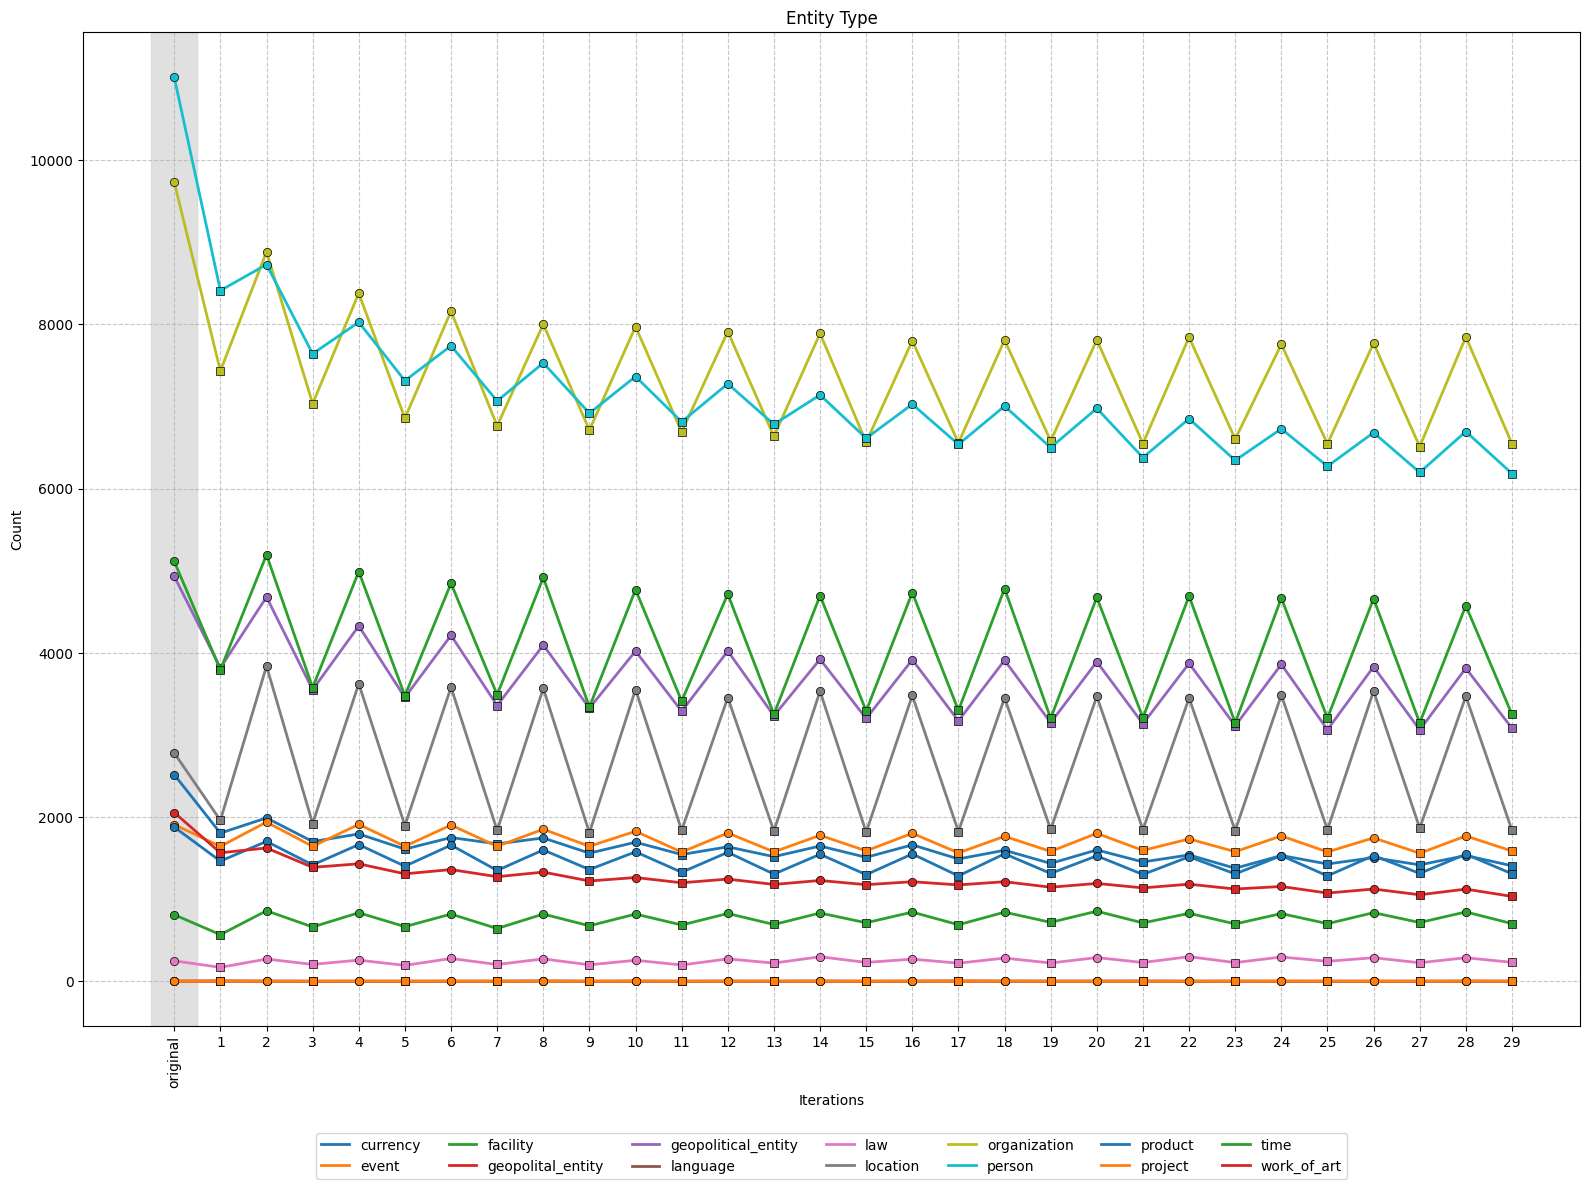

In [142]:
entity_types = [
    "person",
    "organization",

    "time",
    "geopolitical_entity",

    "location",
    
    ]

entity_types = None

plot_entity_types(data_type, entity_types=entity_types, figsize=(16, 12))

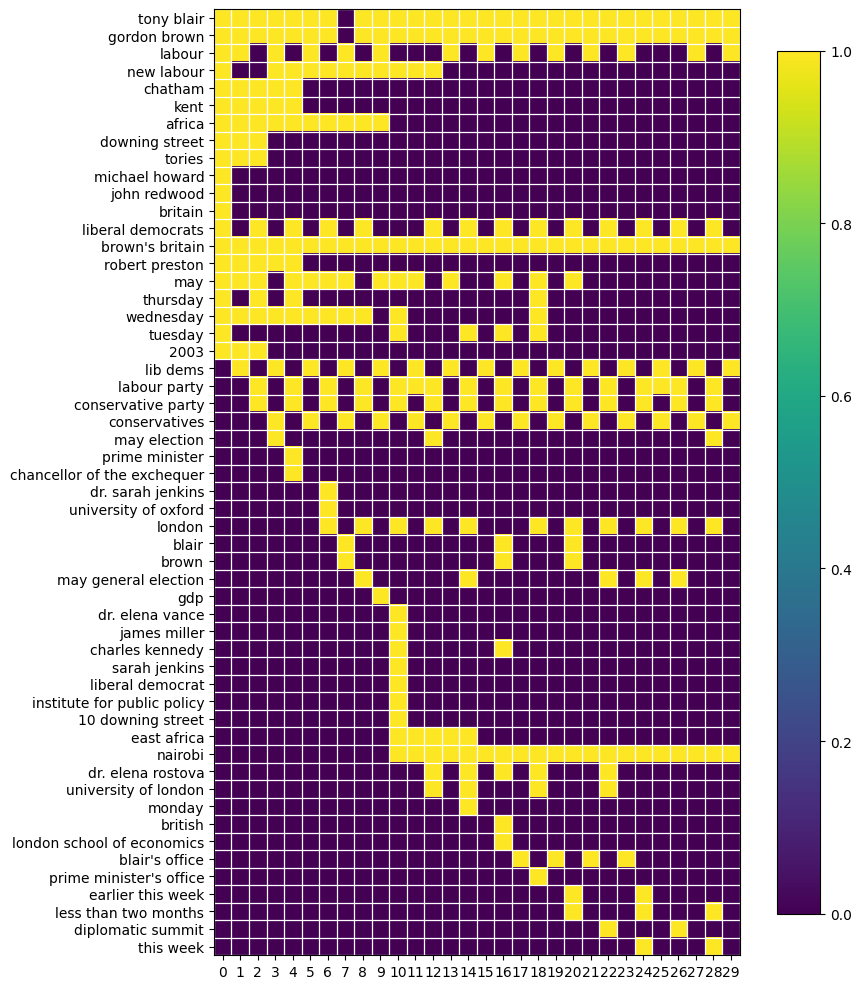

In [143]:
plot_sample_trajectory(data_entity, sample_id=1000, figsize=(10, 10))

(<Figure size 1200x600 with 1 Axes>,
 <Axes: title={'center': 'All Entity Types'}>)

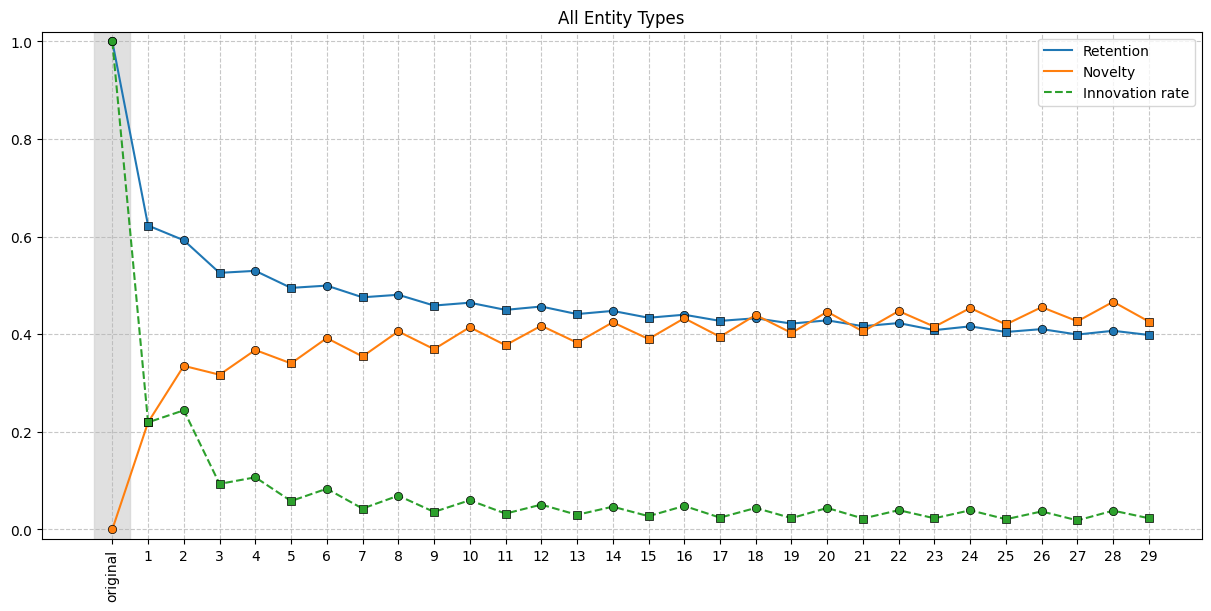

In [145]:
plot_retention_novelty(data_entity, entity_type=None)

(<Figure size 1200x600 with 1 Axes>, <Axes: title={'center': 'work_of_art'}>)

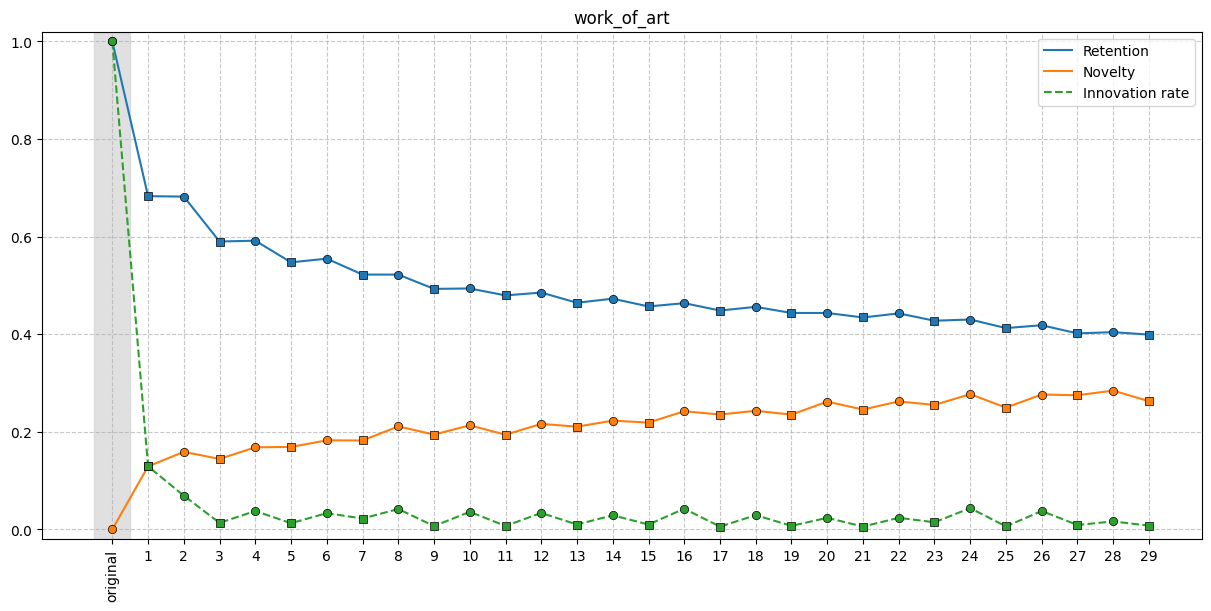

In [147]:
plot_retention_novelty(data_entity, entity_type="work_of_art")

# backup

In [138]:
# backup

# def compare_counters_backup(src: Counter, tgt: Counter):
#     ents = sorted(set(src) | set(tgt))
#     p = np.array([src.get(e, 0) for e in ents], dtype=float)
#     q = np.array([tgt.get(e, 0) for e in ents], dtype=float)
# 
#     S, T = set(src), set(tgt)
#     return {
#         "jaccard_dist": 1 - len(S & T) / len(S | T),
#         "js_divergence": jensenshannon(p / p.sum(), q / q.sum(), base=2) ** 2,
#         "retention": len(S & T) / len(S),                       # original entities kept
#         "retained_mass": sum(src[e] for e in S & T) / sum(src.values()),
#         "novelty": len(T - S) / len(T),                         # new entities in target
#     }
# 
# 
# def plot_retention_novelty_backup(data, entity_type: None | str = None):
#     marker_cycle = ("o", "s")
# 
#     iterations = ["original"] + [col for col in data.iteration.unique() if col.startswith("iteration_")]
# 
#     if entity_type:
#         data = data[data["type"] == entity_type]
# 
#     metrics = []
#     for iteration in iterations:
#         metrics.append(compare_counters_backup(
#             data[data["iteration"] == "original"]["entity"].value_counts().to_dict(),
#             data[data["iteration"] == iteration]["entity"].value_counts().to_dict()
#         ))
# 
#     fig, ax = plt.subplots(1, 1, figsize=(12, 6), layout="constrained")
#     ax.plot(range(len(iterations)), [m["retention"] for m in metrics], label="Retention") # marker="o")
#     for m_idx, m in enumerate(marker_cycle):
#         xs = range(len(iterations))[m_idx::len(marker_cycle)]
#         ys = [m["retention"] for m in metrics][m_idx::len(marker_cycle)]
#         ax.plot(xs, ys, marker=m, color=ax.get_lines()[-1].get_color(), markeredgecolor="black", markeredgewidth=0.5, linestyle="none")
# 
#     ax.plot(range(len(iterations)), [m["novelty"] for m in metrics], label="Novelty") #, marker="s")
#     for m_idx, m in enumerate(marker_cycle):
#         xs = range(len(iterations))[m_idx::len(marker_cycle)]
#         ys = [m["novelty"] for m in metrics][m_idx::len(marker_cycle)]
#         ax.plot(xs, ys, marker=m, color=ax.get_lines()[-1].get_color(), markeredgecolor="black", markeredgewidth=0.5, linestyle="none")
# 
#     ax.set_xticks(range(len(iterations)), ["original"] + list(range(1, len(iterations))))
#     first = ax.get_xticklabels()[0]
#     first.set_rotation(90)
#     first.set_ha("center")
# 
#     ax.grid(which='major', linestyle='--', alpha=0.7)
#     ax.legend()
# 
#     # color the background of the original iteration differently (iter 0)
#     ax.axvspan(-0.5, 0.5, alpha=0.7, color='lightgray')
# 
#     _title = f"{entity_type}" if entity_type else "All Entity Types"
#     ax.set_title(_title)
# 
#     return fig, ax
# 
# plot_retention_novelty_backup(data_entity, entity_type="person")